# Problem 3: 

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN

names = list("ABCDEFGH")
X = np.array([[1,1],[2,1],[1,2],[8,8],[8,9],[25,25],[24,25],[25,24]])

In [5]:
# epsilon-neighborhoods
dist = np.linalg.norm(X[:, None] - X[None], axis=2)
for i, nm in enumerate(names):
    nb = [names[j] for j in np.where(dist[i] <= 2)[0]]
    print(f"{nm}: N_eps = {nb}  -> {'core' if len(nb) >= 2 else 'not core'}")

A: N_eps = ['A', 'B', 'C']  -> core
B: N_eps = ['A', 'B', 'C']  -> core
C: N_eps = ['A', 'B', 'C']  -> core
D: N_eps = ['D', 'E']  -> core
E: N_eps = ['D', 'E']  -> core
F: N_eps = ['F', 'G', 'H']  -> core
G: N_eps = ['F', 'G', 'H']  -> core
H: N_eps = ['F', 'G', 'H']  -> core


Cluster 1: ['A', 'B', 'C']
Cluster 2: ['D', 'E']
Cluster 3: ['F', 'G', 'H']


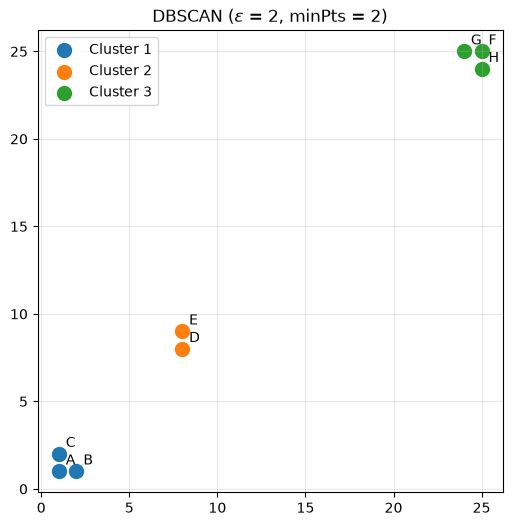

In [6]:
db = DBSCAN(eps=2, min_samples=2).fit(X)
labels = db.labels_
for lab in sorted(set(labels)):
    pts = [names[i] for i in np.where(labels == lab)[0]]
    print("Noise:" if lab == -1 else f"Cluster {lab+1}:", pts)

plt.figure(figsize=(6, 6))
for lab in sorted(set(labels)):
    m = labels == lab
    plt.scatter(X[m, 0], X[m, 1], s=100, label="noise" if lab == -1 else f"Cluster {lab+1}")
for (x, y), nm in zip(X, names):
    plt.annotate(nm, (x, y), xytext=(5, 5), textcoords="offset points")
plt.title("DBSCAN ($\\varepsilon$ = 2, minPts = 2)"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

**Result: 3 clusters, no noise.**
- Cluster 1: {A, B, C}
- Cluster 2: {D, E}
- Cluster 3: {F, G, H}
